# 01. Vision general del proyecto

## Student Success Intelligence

### Predicción temprana de la deserción universitaria y el éxito académico

**Proyecto:** Student Success Intelligence

**Fase:** Comprensión de los datos

**Conjunto de datos:** Predicción de la deserción y el éxito académico de los estudiantes

**Fuente:** UCI Machine Learning Repository / Kaggle

**Objetivo:**

Comprender la estructura del conjunto de datos, identificar sus variables,
evaluar la calidad inicial de los datos e investigar la
variable objetivo antes de desarrollar modelos predictivos.

# 02. Comprensión del problema

## Problema de negocio

La deserción universitaria representa un desafío significativo
para las instituciones de educación superior.

Identificar a los estudiantes que podrían estar en riesgo de abandonar sus estudios
puede facilitar el desarrollo de estrategias de intervención académica preventivas.

## Objetivos analíticos

- Comprender las características demográficas y académicas
de los estudiantes.
- Identificar factores asociados a los resultados académicos.
- Explorar la distribución de los estudiantes según su estado:
deserción, matriculados o graduados.
- Identificar las variables disponibles en las distintas etapas académicas.
- Sentar las bases para el desarrollo de modelos predictivos de alerta temprana.

## Variable objetivo

El conjunto de datos contempla tres posibles estados para los estudiantes:

- Deserción
- Matriculado
- Graduado

Se trata de un problema de clasificación multiclase.


# 03. Descripción del Dataset


El conjunto de datos contiene información a nivel de estudiante, recopilada
en una institución de educación superior portuguesa.

Incluye variables demográficas, socioeconómicas, de matriculación académica
y de rendimiento académico.

| Característica | Valor esperado |
|---|---|
| Observaciones | 4.424 |
| Variables predictoras | 36 |
| Variable objetivo | Objetivo (Target) |
| Clases objetivo | 3 |
| Tipo de problema | Clasificación multiclase |
| Formato de los datos | CSV |

# 04. Importar librerías

In [2]:
# ==========================================
# 04. LIBRERIAS A IMPORTAR
# ==========================================

import sys
from pathlib import Path

import pandas as pd
import numpy as np 

import matplotlib.pyplot as plt 
import seaborn as sns

from IPython.display import display

# Modulos del proyecto
from src.config.settings import (
    DATASET_NAME,
    EXPECTED_COLUMNS,
    EXPECTED_ROWS,
    RAW_DATA_FILE,
    TARGET_COLUMN,
    PROJECT_ROOT,
    DOCS_DATA_DIR
)    
    
from src.ingestion.extract import extract_dataset       # extraer la función creada en el modulo ingestion.py

# Definir paleta del proyecto
COLORS = ["#285F8F", "#E69F42"]



# Configuracion de la visualizacion
sns.set_theme(
    style= "whitegrid",
    context= 'notebook',
    palette= COLORS
    )   

pd.set_option("display.max_columns", None)  # establece mostrar todas las columnas del dataframe

pd.set_option("display.max_rows", 100)      # establece mostrar un máximo de filas de 100

print('Librerías importadas exitosamente.')
print(f'Raíz del proyecto: {PROJECT_ROOT}')
print(f'Nombre del dataset: {DATASET_NAME}')

Librerías importadas exitosamente.
Raíz del proyecto: C:\Users\Usuario\Desktop\Projects\student-success-intelligence
Nombre del dataset: Predict Student's Dropout and Academic Succes


# 05. Extracción de datos

- El conjunto de datos original se almacena en la capa de datos sin procesar.

- El proceso de extracción lee el archivo CSV de origen sin
modificar sus valores originales.

- El DataFrame extraído se utilizará para la inspección inicial
de los datos y la evaluación de su calidad.

In [3]:
# ==========================================
# DATA EXTRACTION
# ==========================================

print(f'Dataset location: {RAW_DATA_FILE}')

df = extract_dataset(sep=';')

print('Dataset extraído existosamente.')

Dataset location: C:\Users\Usuario\Desktop\Projects\student-success-intelligence\data\raw\dataset.csv
Dataset extraído existosamente.


# 06. Inspeccion inicial de los datos

Examinaremos la primera y la última observación,
las dimensiones del conjunto de datos y los nombres de las columnas
para comprender la estructura inicial de los datos de origen.

In [4]:
# Dimensiones del dataset
print(f'Dataset shape: {df.shape}')

# Número de observaciones
print(f'Número de registros: {df.shape[0]}')

# Número de columnas
print(f'Número de columnas {df.shape[1]}')

Dataset shape: (4424, 37)
Número de registros: 4424
Número de columnas 37


In [5]:
# Primeras observaciones
display(print(df.head()))

   Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance  Previous qualification  \
0                           1                       1   
1                           1                       1   
2                           1                       1   
3                           1                       1   
4                           0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   
2                           122.0     

None

In [6]:
# Ultimas observaciones
display(print(df.tail()))

      Marital status  Application mode  Application order  Course  \
4419               1                 1                  6    9773   
4420               1                 1                  2    9773   
4421               1                 1                  1    9500   
4422               1                 1                  1    9147   
4423               1                10                  1    9773   

      Daytime/evening attendance  Previous qualification  \
4419                           1                       1   
4420                           1                       1   
4421                           1                       1   
4422                           1                       1   
4423                           1                       1   

      Previous qualification (grade)  Nacionality  Mother's qualification  \
4419                           125.0            1                       1   
4420                           120.0          105                     

None

# 07. Estructura y tipos de datos

Examinaremos el esquema del conjunto de datos, los tipos de datos
y el uso de memoria.

Este análisis ayudará a identificar columnas que podrían
requerir una investigación más detallada durante la preparación de los datos.

In [7]:
# Nombres de columnas
display(pd.DataFrame({
    "column_name": df.columns,
    "data_type": df.dtypes.astype(str).values
}))

# Información del dataset
df.info()

# Estadística descriptiva
display(df.describe(include= "all").T)

,column_name,data_type
0,Marital status,int64
1,Application mode,int64
2,Application order,int64
3,Course,int64
4,Daytime/evening attendance,int64
5,Previous qualification,int64
6,Previous qualification (grade),float64
7,Nacionality,int64
8,Mother's qualification,int64
9,Father's qualification,int64


<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Marital status,4424.0,NaN,NaN,NaN,1.178571,0.605747,1.0,1.0,1.0,1.0,6.0
Application mode,4424.0,NaN,NaN,NaN,18.669078,17.484682,1.0,1.0,17.0,39.0,57.0
Application order,4424.0,NaN,NaN,NaN,1.727848,1.313793,0.0,1.0,1.0,2.0,9.0
Course,4424.0,NaN,NaN,NaN,8856.642631,2063.566416,33.0,9085.0,9238.0,9556.0,9991.0
Daytime/evening attendance,4424.0,NaN,NaN,NaN,0.890823,0.311897,0.0,1.0,1.0,1.0,1.0
Previous qualification,4424.0,NaN,NaN,NaN,4.577758,10.216592,1.0,1.0,1.0,1.0,43.0
Previous qualification (grade),4424.0,NaN,NaN,NaN,132.613314,13.188332,95.0,125.0,133.1,140.0,190.0
Nacionality,4424.0,NaN,NaN,NaN,1.873192,6.914514,1.0,1.0,1.0,1.0,109.0
Mother's qualification,4424.0,NaN,NaN,NaN,19.561935,15.603186,1.0,2.0,19.0,37.0,44.0
Father's qualification,4424.0,NaN,NaN,NaN,22.275316,15.343108,1.0,3.0,19.0,37.0,44.0


# 08. Evaluación de la calidad de los datos

El objetivo de esta sección es evaluar la
calidad inicial del conjunto de datos.

Analizaremos:

- Valores faltantes.
- Registros duplicados.
- Nombres de columnas duplicados.
- Tipos de datos.
- Valores inesperados en la variable objetivo.

En esta etapa no se realizarán tareas de
limpieza ni transformaciones.

In [8]:
# valores faltantes
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "missing_count": missing_values,
    "missing_percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        by= "missing_count",
        ascending=False
    )
)

# Registros duplicados
duplicate_records = df.duplicated().sum()

print(f'registros duplicados: {duplicate_records}')

,missing_count,missing_percentage
Marital status,0,0.0
Application mode,0,0.0
Application order,0,0.0
Course,0,0.0
Daytime/evening attendance,0,0.0
Previous qualification,0,0.0
Previous qualification (grade),0,0.0
Nacionality,0,0.0
Mother's qualification,0,0.0
Father's qualification,0,0.0


registros duplicados: 0


# 09. Análisis de la variable objetivo

La variable objetivo representa el resultado final del estudiante.

Las tres clases posibles son:

- Abandono
- Matriculado
- Graduado

Examinaremos las frecuencias y proporciones de las clases
para comprender la distribución del objetivo de predicción.

Este análisis también ayudará a identificar un posible
desequilibrio entre las clases.

In [9]:
# Frecuencia de la variable objetivo
target_counts = df[TARGET_COLUMN].value_counts()

# Porcentaje de la variable objetivo
target_percentage = (
    df[TARGET_COLUMN]
    .value_counts(normalize=True)   # el valores de 0 a 1
    .mul(100)                       # multiplicado x 100 = porcentaje
)

target_summary = pd.DataFrame({
    "students": target_counts,
    "percentage": target_percentage.round(2)
})

display(target_summary)

,students,percentage
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


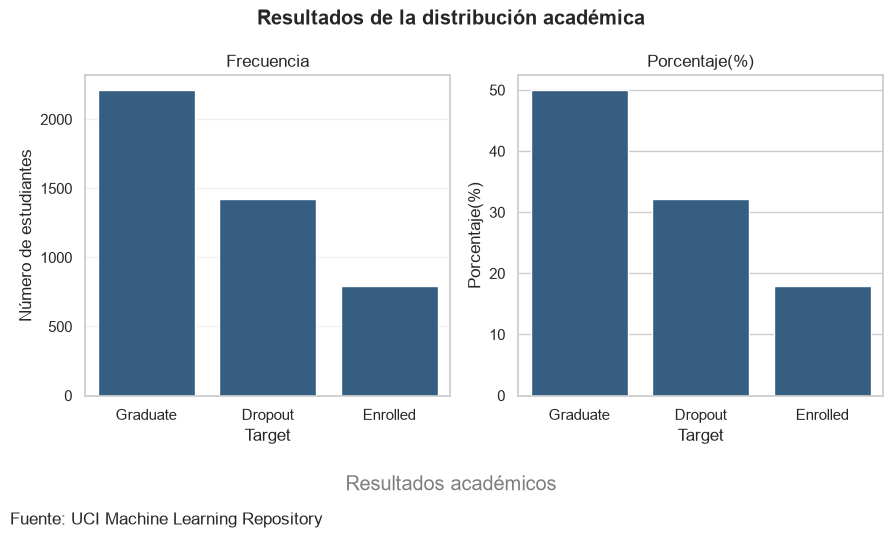

,students,percentage
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


In [10]:
# Crear la figura y los axes
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(9, 5))

# Gráfico Distribución del objetivo
g = sns.countplot(
    data=df,
    x=TARGET_COLUMN,
    order=target_counts.index,
    ax=ax[0]
)

# Títulos y ejes
g.set_title("Frecuencia")
#g.set_xlabel("Resultados de los estudiantes")
g.set_ylabel("Número de estudiantes")


p = sns.barplot(
    x = target_percentage.index,
    y = target_percentage.values,
    ax=ax[1]
)

p.set_title("Porcentaje(%)")
p.set_ylabel("Porcentaje(%)")


fig.suptitle("Resultados de la distribución académica", fontweight = 'bold')    # titulo superior general
fig.supxlabel("Resultados académicos", color = 'black', alpha=0.5)                          # titulo inferior general

# Texto inferior
fig.text(
    0.01, -0.05,
    "Fuente: UCI Machine Learning Repository",
    ha="left"
)

# Diseño
g.grid(axis= 'y', alpha=0.3)
fig.tight_layout()


# Guardar figura
fig.savefig(
    f"{DOCS_DATA_DIR}/images/figures/data_understanding/distribucion_academica.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

display(target_summary)

# 10. Hallazgos iniciales

In [11]:
# ==========================================
# INITIAL FINDINGS
# ==========================================

print("DATASET VISTA GENERAL")
print("-" * 45)

print(f"Observations: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")
print(f"Predictor variables: {df.shape[1] - 1}")

print("\nCALIDAD DE LOS DATOS")
print("-" * 45)

print(f"Valores faltantes: {missing_values.sum():,}")
print(f"Duplicate records: {duplicate_records.sum():,}")

print("\nDISTRIBUCION DE LA VARIABLE OBJETIVO")
print("-" * 45)

for resultado, conteo in target_counts.items():
    porcentaje = target_percentage[resultado]
    
    print(
        f"{resultado}: {conteo:,} estudiantes "
        f"({porcentaje:.2f}%)"
)
    
print("\nVERIFICAR LA ESTRUCTURA ESPERADA")
print("-" * 45)

print(f'Observaciones esperadas',
      df.shape[0] == EXPECTED_ROWS
      )

print(f'Variables predictoras esperadas',
      df.shape[1] - 1 == EXPECTED_COLUMNS
      )

print(f'La columna objetivo existe:',
      TARGET_COLUMN in df.columns
      )


objetivos_esperados = {
    "Dropout",
    "Enrolled",
    "Graduate"
}

objetivos_observados = set(
    df[TARGET_COLUMN].dropna().unique()
)

print('Clases objetivo esperadas',
      objetivos_observados == objetivos_esperados
      )

DATASET VISTA GENERAL
---------------------------------------------
Observations: 4,424
Total columns: 37
Predictor variables: 36

CALIDAD DE LOS DATOS
---------------------------------------------
Valores faltantes: 0
Duplicate records: 0

DISTRIBUCION DE LA VARIABLE OBJETIVO
---------------------------------------------
Graduate: 2,209 estudiantes (49.93%)
Dropout: 1,421 estudiantes (32.12%)
Enrolled: 794 estudiantes (17.95%)

VERIFICAR LA ESTRUCTURA ESPERADA
---------------------------------------------
Observaciones esperadas True
Variables predictoras esperadas False
La columna objetivo existe: True
Clases objetivo esperadas True


# 11. Conclusiones iniciales

### Estructura del conjunto de datos

La inspección inicial proporciona una visión general de las dimensiones, las variables y los tipos de datos del conjunto de datos.

### Calidad de los datos

- No hay valores faltantes.
- No hay registros duplicados.
- Se comprueba que hay 36 atributos + la variable objetivo.

### Distribución de la variable objetivo

- La distribución de las categorías «abandono», «inscrito» y «graduado» determinará la estrategia de clasificación inicial y las métricas de evaluación.
- De los 4424 registros, el 49.93% son graduados, el 32,12% abandonan la carrera y 17.95% están inscritos
### Consideraciones sobre el modelado predictivo

El conjunto de datos contiene variables recopiladas en diferentes etapas académicas.

Por lo tanto, la selección de variables debe tener en cuenta el momento en que cada una de ellas pasa a estar disponible.

Esto es fundamental para evitar la «fuga de datos» (*data leakage*) y garantizar que los escenarios predictivos representen oportunidades realistas de intervención académica.

### Próximos pasos

- Completar el diccionario de datos.
- Identificar las variables disponibles en el momento de la inscripción.
- Identificar las variables relacionadas con el rendimiento durante el primer semestre.
- Definir las reglas iniciales de calidad de los datos.
- Preparar la etapa de transformación (ETL).